# TD6 — Exercice 3 : Variogramme 2D, krigeage et simulation (nuage de points Gold)

Cet exercice étudie la variable **Values** sur un **nuage de 274 points 2D**,
à partir du fichier `gold_2D_points.csv`, puis réalise le **krigeage** (SK, OK, UK)
et la **simulation par bandes tournantes (TBS)**.

**Nature de la donnée** : `Values` est une **variable régionalisée standardisée** (moyenne ≈ 0, variance ≈ 1), connue seulement en **274 points dispersés**. Sert à apprendre l'**estimation** (krigeage) et la **simulation** là où la variable n'est pas mesurée.

## Aperçu des fonctions utilisées

Petit récapitulatif de ce que fait chaque fonction clé de ce notebook :

| Fonction | Rôle |
|---|---|
| `pd.read_csv(...)` | Charge le nuage de 274 points 2D (variable `Values`) |
| `gutils.creer_db_gstlearn(...)` | Crée la base de données gstlearn (`Db`) des points |
| `gl.VarioParam` / `gl.Vario.compute(...)` | Définit et calcule le variogramme **expérimental** |
| `gl.Model().fit(...)` | Ajuste le **modèle** (automatique + réglage manuel via widget) |
| `gl.db_vmap(...)` | Carte variographique (étude de l'**anisotropie**) |
| `gutils.creer_grille(...)` | Crée la **grille d'estimation** (100×100) |
| `gl.NeighUnique.create()` | Définit le **voisinage** de krigeage |
| `gl.kriging(...)` | Réalise le **krigeage** : Simple (SK), Ordinaire (OK), Universel (UK) |
| `gl.simtub(...)` | Simulation conditionnelle par **bandes tournantes (TBS)** |


## 1. Chargement des données

Lecture du fichier `gold_2D_points.csv` (274 points 2D).

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gstlearn as gl
import gstlearn.plot as gp
import ipywidgets as widgets
from ipywidgets import interactive_output

# Ajout du chemin d'importation pour le module geostat_utils (remonte de gold_td6/ jusqu'à src/)
sys.path.append(os.path.abspath(os.path.join("..", "..")))
import geostat_utils as gutils

#---- Chargement des données (Exercice 3 : nuage de points Gold 2D) ----
points_gold_2D = pd.read_csv('../../../data/gold_2D_points.csv')
display(points_gold_2D.head(3))

,NAME,X,Y,Z,PART_ID,Values
0,2DPoints,0.194930,4.680289,3999.998047,1,1.101290
1,2DPoints,0.444480,4.730199,3999.998047,1,-0.226447
2,2DPoints,0.427843,4.472330,3999.998047,1,0.625209


## 2. Contexte
Les données proviennent du **2DPoints Gold** exporté depuis SKUA-Gocad. La variable étudiée est **Values** (274 points, coordonnées X et Y en km) Les données sont déjà **normalisées** — distribution gaussienne centrée réduite.

## 3. Visualisation spatiale des points

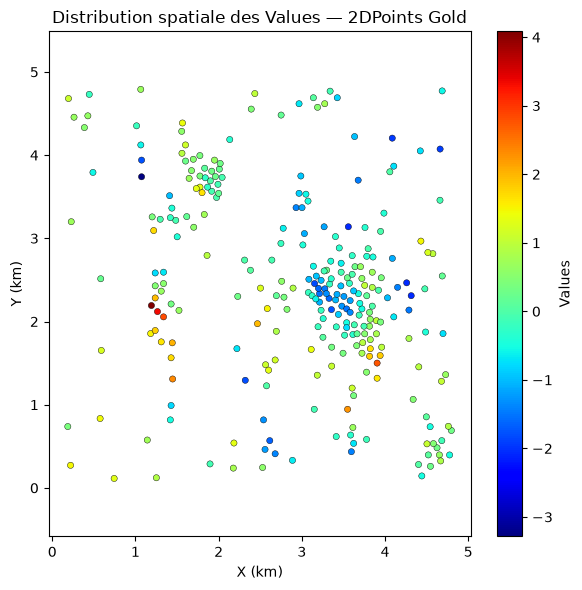

In [2]:
# ---- Carte spatiale des points Gold 2D ----
plt.figure(figsize=(6, 6))
plt.scatter(points_gold_2D['X'], points_gold_2D['Y'],
            c=points_gold_2D['Values'],
            cmap='jet', s=20,
            edgecolor='k', linewidth=0.3)
plt.colorbar(label='Values')
plt.xlabel('X (km)')
plt.ylabel('Y (km)')
plt.title('Distribution spatiale des Values — 2DPoints Gold')
plt.axis('equal')
plt.tight_layout()
plt.show()

## 4. Histogramme et courbe cumulative

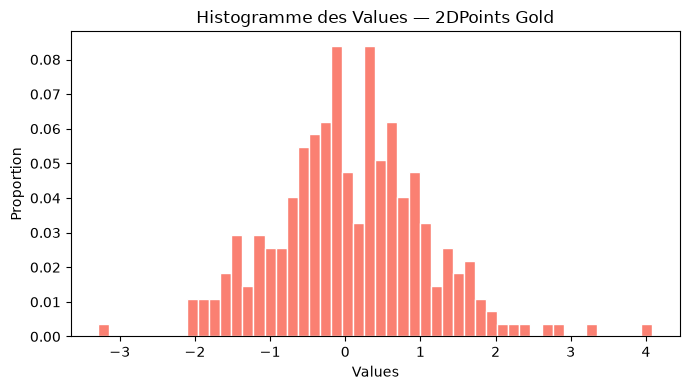

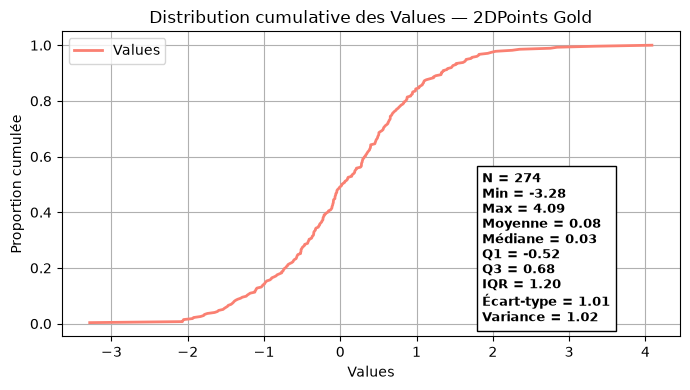

In [3]:
# ---- Histogramme des Values ----
gold_vals = points_gold_2D['Values']

plt.figure(figsize=(7, 4))
plt.hist(gold_vals, bins=50,
         weights=np.ones(len(gold_vals))/len(gold_vals),
         color='salmon', edgecolor='white')
plt.title("Histogramme des Values — 2DPoints Gold")
plt.xlabel("Values")
plt.ylabel("Proportion")
plt.tight_layout()
plt.show()

# ---- Statistiques ----
nombre_mesures_gold2d     = len(gold_vals)
min_gold2d                = np.min(gold_vals)
max_gold2d                = np.max(gold_vals)
moyenne_gold2d            = np.mean(gold_vals)
mediane_gold2d            = np.median(gold_vals)
premier_quartile_gold2d   = np.percentile(gold_vals, 25)
troisieme_quartile_gold2d = np.percentile(gold_vals, 75)
IQR_gold2d                = troisieme_quartile_gold2d - premier_quartile_gold2d
ecart_type_gold2d         = np.std(gold_vals, ddof=1)
variance_gold2d           = np.var(gold_vals, ddof=1)
gold2d_trie               = np.sort(gold_vals)
gold2d_cumulative         = np.arange(1, len(gold2d_trie)+1) / len(gold2d_trie)

# ---- Distribution cumulative ----
plt.figure(figsize=(7, 4))
plt.plot(gold2d_trie, gold2d_cumulative,
         color='salmon', linewidth=2, label='Values')
plt.title("Distribution cumulative des Values — 2DPoints Gold")
plt.xlabel("Values")
plt.ylabel("Proportion cumulée")
plt.legend(loc='upper left')

text_stats = (
    f"N = {nombre_mesures_gold2d}\n"
    f"Min = {min_gold2d:.2f}\n"
    f"Max = {max_gold2d:.2f}\n"
    f"Moyenne = {moyenne_gold2d:.2f}\n"
    f"Médiane = {mediane_gold2d:.2f}\n"
    f"Q1 = {premier_quartile_gold2d:.2f}\n"
    f"Q3 = {troisieme_quartile_gold2d:.2f}\n"
    f"IQR = {IQR_gold2d:.2f}\n"
    f"Écart-type = {ecart_type_gold2d:.2f}\n"
    f"Variance = {variance_gold2d:.2f}"
)
plt.text(0.68, 0.05, text_stats,
    transform=plt.gca().transAxes,
    fontsize=9, fontweight='bold',
    bbox=dict(facecolor='white', edgecolor='black')
)
plt.grid()
plt.tight_layout()
plt.show()

## 5. Création de la base gstlearn (2D)

In [4]:
# ---- Création de la base gstlearn depuis les points Gold 2D (fonction factorisée) ----
gl.defineDefaultSpace(gl.ESpaceType.RN, 2)

db_gold2d = gutils.creer_db_gstlearn(
    points_gold_2D,
    variables=["X", "Y", "Values"],
    noms_locators=["x1", "x2", "z1"]
)
print(db_gold2d)


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 4
Total number of samples      = 274

Variables
---------
Column = 0 - Name = rank - Locator = NA
Column = 1 - Name = X - Locator = x1
Column = 2 - Name = Y - Locator = x2
Column = 3 - Name = Values - Locator = z1



## 6. Variogramme expérimental 2D

### 6.1 Définir les paramètres du variogramme en 2D

In [5]:
#----Définition des paramètres du variogramme — 2DPoints Gold----

etendue_x_gold2d = points_gold_2D["X"].max() - points_gold_2D["X"].min()
etendue_y_gold2d = points_gold_2D["Y"].max() - points_gold_2D["Y"].min()

diagonale_gold2d = np.sqrt(etendue_x_gold2d**2 + etendue_y_gold2d**2)
nombre_classe_gold2d = 17
taille_classe_gold2d = 0.291066

print(f"Longueur du domaine selon X : {etendue_x_gold2d:.3f} km")
print(f"Longueur du domaine selon Y : {etendue_y_gold2d:.3f} km")
print(f"Diagonale du domaine       : {diagonale_gold2d:.2f} km")
print(f"Nombre de classes (nlag)   : {nombre_classe_gold2d}")
print(f"Taille d'une classe (dlag) : {taille_classe_gold2d} km")

Longueur du domaine selon X : 4.611 km
Longueur du domaine selon Y : 4.677 km
Diagonale du domaine       : 6.57 km
Nombre de classes (nlag)   : 17
Taille d'une classe (dlag) : 0.291066 km


### 6.2 Calcul du variogramme omnidirectionnel

In [6]:
#----Calcul du variogramme expérimental omnidirectionnel — 2DPoints Gold----
params_vario_omni_gold2d = gl.VarioParam.createOmniDirection(
    nlag=nombre_classe_gold2d,
    dlag=taille_classe_gold2d,
    toldis=0.1
)
vario_exp_omni_gold2d = gl.Vario(params_vario_omni_gold2d)
err = vario_exp_omni_gold2d.compute(db_gold2d)
print(vario_exp_omni_gold2d)


Variogram characteristics
Number of variable(s)       = 1
Number of direction(s)      = 1
Space dimension             = 2
Variable(s)                 = [Values]

Variance-Covariance Matrix      1.014

Direction #1
------------
Number of lags              = 17
Direction coefficients      =       1.000      0.000
Direction angles (degrees)  =       0.000
Tolerance on direction      =      90.000 (degrees)
Calculation lag             =       0.291
Tolerance on distance       =      10.000 (Percent of the lag value)

For variable 1
       Rank     Npairs   Distance      Value
          1    396.000      0.291      0.580
          2    574.000      0.582      0.859
          3    567.000      0.873      1.037
          4    627.000      1.165      1.009
          5    635.000      1.455      0.958
          6    665.000      1.746      0.983
          7    777.000      2.037      1.205
          8    742.000      2.329      1.167
          9    627.000      2.620      0.993
         10    

Variance Values = 1.0175


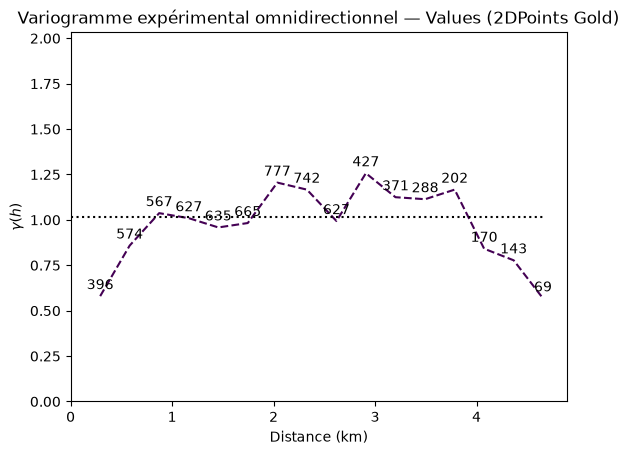

In [7]:
#----Affichage du variogramme expérimental omnidirectionnel (avec nombre de paires)----

variance_gold2d = np.var(points_gold_2D["Values"], ddof=1)
print(f"Variance Values = {variance_gold2d:.4f}")

ax = gp.varmod(vario_exp_omni_gold2d, showPairs=True)
ax.set_ylim(0, variance_gold2d * 2)
plt.xlabel("Distance (km)")
plt.ylabel(r"$\gamma(h)$")
plt.title("Variogramme expérimental omnidirectionnel — Values (2DPoints Gold)")
plt.show()


### 6.3 Nuage de variogramme (Variogram Cloud)


Data Base Grid Characteristics

Data Base Summary
-----------------
File is organized as a regular grid
Space dimension              = 2
Number of Columns            = 4
Total number of samples      = 10000

Grid characteristics:
---------------------
Origin :       0.000      0.000
Mesh   :       0.066      0.031
Number :         100        100

Variables
---------
Column = 0 - Name = rank - Locator = NA
Column = 1 - Name = x1 - Locator = x1
Column = 2 - Name = x2 - Locator = x2
Column = 3 - Name = Cloud.Values - Locator = NA


Variogram characteristics
Number of variable(s)       = 1
Number of direction(s)      = 1
Space dimension             = 2
Variable(s)                 = [Values]

Variance-Covariance Matrix      1.014

Direction #1
------------
Number of lags              = 17
Direction coefficients      =       1.000      0.000
Direction angles (degrees)  =       0.000
Tolerance on direction      =      90.000 (degrees)
Calculation lag             =       0.291
Tolerance on di

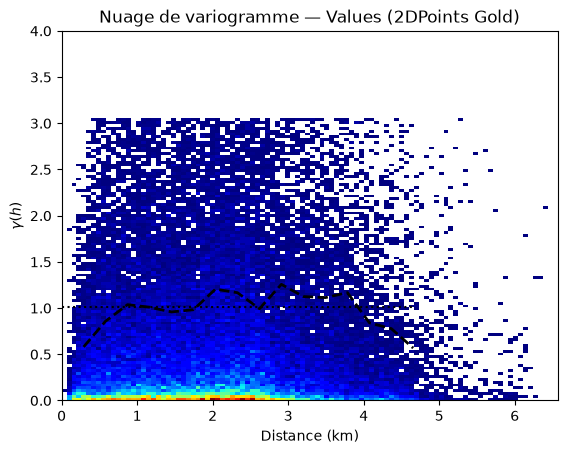

In [8]:
#---- Nuage de variogramme + Variogramme expérimental — Values (2DPoints Gold) ----
gl.defineDefaultSpace(gl.ESpaceType.RN, 2)

db_gold2d.setLocator("Values", gl.ELoc.Z)

# ---- Nuage de variogramme ----
varioParamOmni_cloud_gold = gl.VarioParam.createOmniDirection(
    nlag=100,
    dlag=0.291066
)
grid_cloud_gold = gl.db_vcloud(db_gold2d, varioParamOmni_cloud_gold)
print(grid_cloud_gold)

# ---- Variogramme expérimental omnidirectionnel ----
params_vario_omni_gold2d = gl.VarioParam.createOmniDirection(
    nlag=nombre_classe_gold2d,
    dlag=taille_classe_gold2d,
    toldis=0.1
)
vario_exp_omni_gold2d = gl.Vario(params_vario_omni_gold2d)
err = vario_exp_omni_gold2d.compute(db_gold2d)
print(vario_exp_omni_gold2d)
# ---- Affichage superposé ----
gp.plot(grid_cloud_gold, "Cloud.Values", cmap="jet")   
ax = plt.gca()
ax.varmod(vario_exp_omni_gold2d, color="black", linewidth=2)  
plt.title("Nuage de variogramme — Values (2DPoints Gold)")
plt.xlabel("Distance (km)")
plt.ylabel(r"$\gamma(h)$")
plt.ylim(0, 4)
plt.show()

## 7.Ajustement automatique du modèle

### 7.1 Modèle Sphérique sans nugget

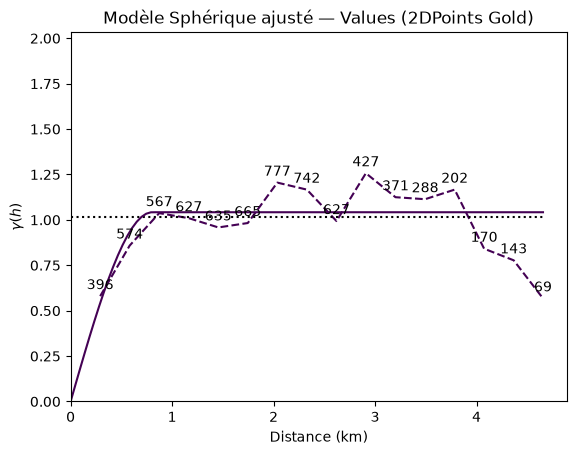


Model characteristics
Space dimension              = 2
Number of variable(s)        = 1
Number of basic structure(s) = 1
Number of drift function(s)  = 0
Number of drift equation(s)  = 0

Covariance Part
---------------
Spherical
- Sill         =       1.042
- Range        =       0.804
Total Sill     =       1.042
Known Mean(s)      0.000



In [9]:
#----Ajustement automatique - Modèle Sphérique sans nugget----
model_spherique_gold2d = gl.Model()
err = model_spherique_gold2d.fit(vario_exp_omni_gold2d, types=[gl.ECov.SPHERICAL])
gutils.afficher_variogramme(vario_exp_omni_gold2d, model_spherique_gold2d,
    "Modèle Sphérique ajusté — Values (2DPoints Gold)", variance_gold2d)

### 7.2 Modèle Sphérique sans nugget

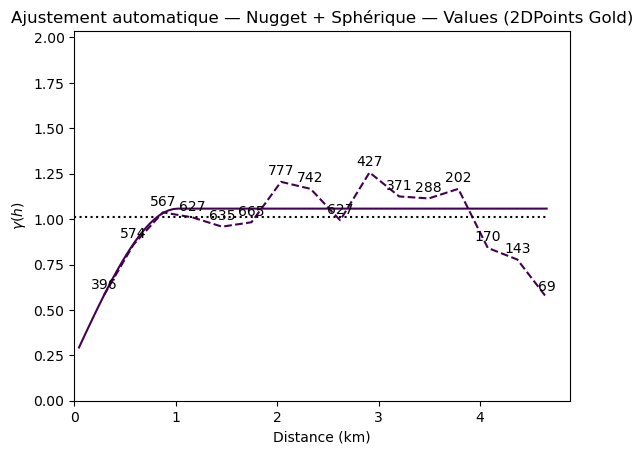


Model characteristics
Space dimension              = 2
Number of variable(s)        = 1
Number of basic structure(s) = 2
Number of drift function(s)  = 0
Number of drift equation(s)  = 0

Covariance Part
---------------
Nugget Effect
- Sill         =       0.237
Spherical
- Sill         =       0.821
- Range        =       1.021
Total Sill     =       1.058
Known Mean(s)      0.000



In [10]:
#----Ajustement automatique - Nugget + Sphérique----
model_nugget_spherique_gold2d = gl.Model()
err = model_nugget_spherique_gold2d.fit(vario_exp_omni_gold2d,
                                        types=[gl.ECov.NUGGET, gl.ECov.SPHERICAL])
gutils.afficher_variogramme(vario_exp_omni_gold2d, model_nugget_spherique_gold2d,
    "Ajustement automatique — Nugget + Sphérique — Values (2DPoints Gold)",
    variance_gold2d)

### 7.3 Ajustement manuel interactif

Le widget ci-dessous permet de régler **manuellement** les paramètres du modèle :

- **Modèle** : Sphérique, Exponentiel ou Gaussien
- **Nugget** : effet de pépite (proportion de la variance)
- **Portée** : distance à laquelle le variogramme atteint le palier

In [11]:
calage_gold2d = gutils.creer_widget_calage_variogramme(
    vario_exp_omni_gold2d, variance_gold2d,
    valeurs_defaut={
        'Spherique':   (0.25, 0.80),
        'Exponentiel': (0.15, 1.20),
        'Gaussien':    (0.15, 0.60),
    },
    facteur_correction=variance_gold2d,
)

In [12]:
model_final_gold2d = calage_gold2d.model
print(model_final_gold2d)


Model characteristics
Space dimension              = 2
Number of variable(s)        = 1
Number of basic structure(s) = 2
Number of drift function(s)  = 0
Number of drift equation(s)  = 0

Covariance Part
---------------
Nugget Effect
- Sill         =       0.254
Spherical
- Sill         =       0.763
- Range        =       0.800
Total Sill     =       1.018
Known Mean(s)      0.000



## 8. Carte variographique (Variogram Map)

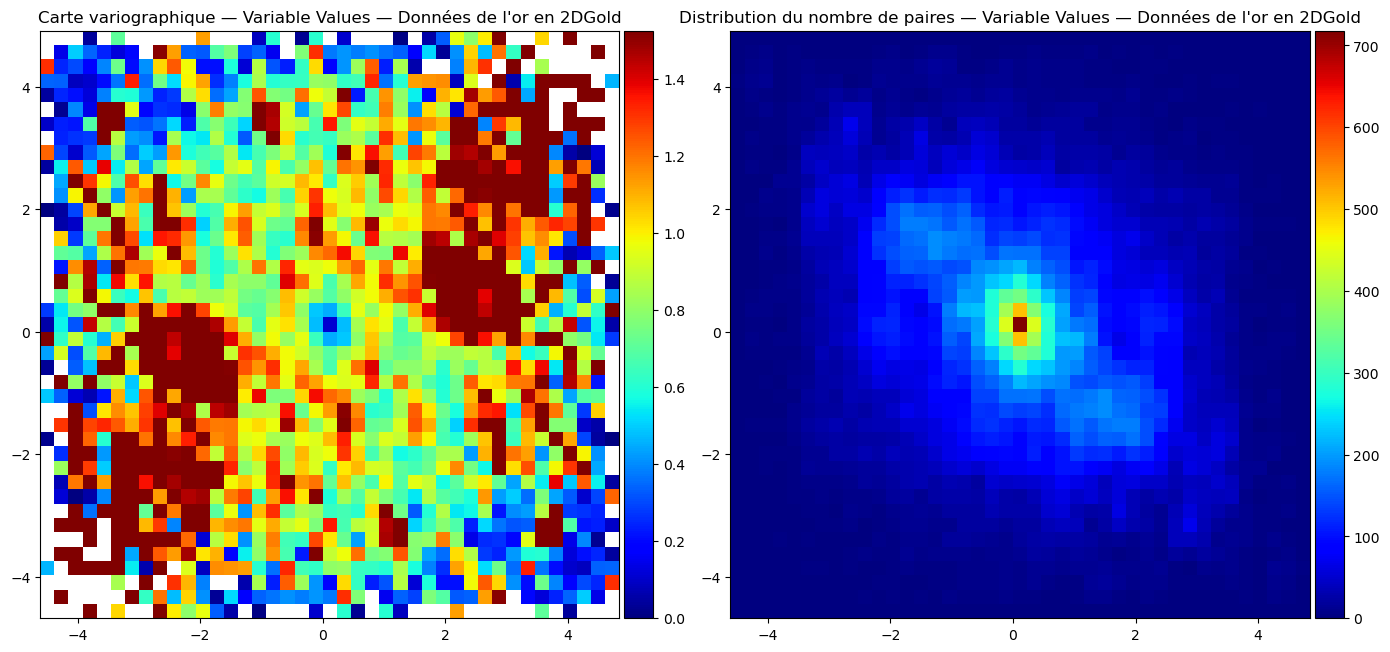

In [13]:
#----Affichage de la Carte variographique (Variogram Map) — 2DPoints Gold----
# Affiche les valeurs du variogramme dans toutes les directions
# simultanément pour identifier les directions d'anisotropie

db_gold2d.setLocator("Values", gl.ELoc.Z)

grid_map_gold2d = gl.db_vmap(db_gold2d)
fig, ax = gp.init(1, 2, figsize=(14, 7), flagEqual=True)
ax[0].raster(grid_map_gold2d, flagLegend=True, cmap="jet", vmin=0, vmax=variance_gold2d * 1.5)
ax[0].decoration(title="Carte variographique — Variable Values — Données de l'or en 2DGold")

#-----carte du nombre de paires -----
ax[1].raster(grid_map_gold2d, name="VMAP.Values.Nb", flagLegend=True, cmap="jet")
ax[1].decoration(title="Distribution du nombre de paires — Variable Values — Données de l'or en 2DGold")
plt.tight_layout()
plt.show()
db_gold2d.setLocator("Values", gl.ELoc.Z)


## 9. Variogramme directionnel (anisotropie)

La carte variographique montre une anisotropie dans la direction NW-SE. On calcule le variogramme dans **2 directions** :

- **Direction 135°** — direction principale (grande portée)
- **Direction 45°** — direction perpendiculaire (petite portée)

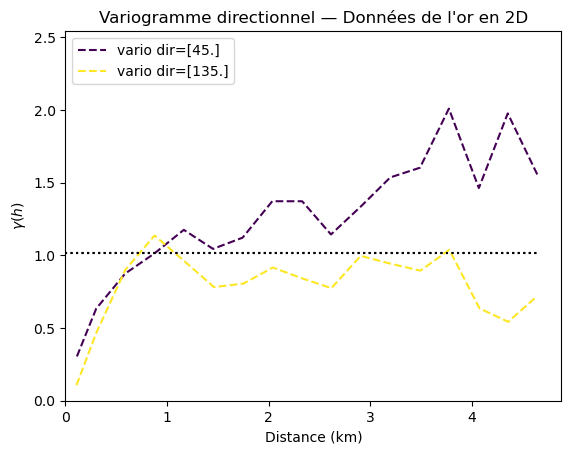

In [14]:
#----Variogramme directionnel en deux directions principales----
varioparam_dir_gold2d = gl.VarioParam()
direction_45_gold2d  = gl.DirParam.create(nlag=nombre_classe_gold2d, dlag=taille_classe_gold2d, tolang=22.5, codir=[1, 1])    
direction_135_gold2d = gl.DirParam.create(nlag=nombre_classe_gold2d, dlag=taille_classe_gold2d, tolang=22.5, codir=[-1, 1])   

varioparam_dir_gold2d.addDir(direction_45_gold2d)
varioparam_dir_gold2d.addDir(direction_135_gold2d)

vario_exp_dir_gold2d = gl.Vario(varioparam_dir_gold2d)
err = vario_exp_dir_gold2d.compute(db_gold2d)

#----Affichage----
gp.varmod(vario_exp_dir_gold2d)
plt.ylim(0, variance_gold2d * 2.5)
plt.legend(loc='upper left')
plt.xlabel("Distance (km)")
plt.ylabel(r"$\gamma(h)$")
plt.title("Variogramme directionnel — Données de l'or en 2D")
plt.show()

## 10. Krigeage

### 10.1 Création de la grille d'estimation

In [15]:
# ---- Création de la grille d'estimation (fonction factorisée) ----
# Équivalent au voxet dans SKUA-Gocad (100 x 100 cellules sur l'emprise des points)
grid_gold = gutils.creer_grille(points_gold_2D, nx=100, ny=100)
print(grid_gold)


Data Base Grid Characteristics

Data Base Summary
-----------------
File is organized as a regular grid
Space dimension              = 2
Number of Columns            = 3
Total number of samples      = 10000

Grid characteristics:
---------------------
Origin :       0.187      0.114
Mesh   :       0.046      0.047
Number :         100        100

Variables
---------
Column = 0 - Name = rank - Locator = NA
Column = 1 - Name = x1 - Locator = x1
Column = 2 - Name = x2 - Locator = x2



### 10.2 Krigeage (SK, OK, UK)

In [16]:
gutils.krigeage_sk_ok_uk(
    dbin=db_gold2d, dbout=grid_gold,
    model_base=model_final_gold2d, nom_variable="Values"
)
gutils.creer_widget_cartes_krigeage(
    dbout=grid_gold, dbin=db_gold2d,
    nom_variable="Values", cmap="PiYG"
)

TypeError: Db.getNames() missing 1 required positional argument: 'names'

## 11. Simulation par bandes tournantes (TBS)

In [ ]:
prefixe_gold = gutils.simulation_bandes_tournantes(
    dbin=db_gold2d, dbout=grid_gold,
    model_base=model_final_gold2d, nom_variable="Values"
)
gutils.creer_widget_realisations(
    dbout=grid_gold, dbin=db_gold2d,
    prefixe=prefixe_gold, nom_variable="Values", cmap="PiYG"
)